# Plotting: N-Schools experiments

Load sweep results from pickle and plot iteration count / wallclock vs T.

In [28]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [29]:
# Use TeX.
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
    }
)

# Configure font sizes.
SMALL_SIZE = 7 + 1
MEDIUM_SIZE = 8 + 1
BIGGER_SIZE = 10 + 1
plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=SMALL_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=MEDIUM_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)

# Configure the line styles, colors etc.
cols = {
    "Sequential": "tab:green",
    "DEER": "tab:red",
    "quasi-DEER": "tab:orange",
    "Picard": "tab:brown",
    "Jacobi": "tab:gray",
    "Broyden-DEER": "tab:blue",
    "Accel. Broyden": "tab:purple",
}
lins = {
    "Sequential": "-",
    "DEER": "-",
    "quasi-DEER": "-",
    "Picard": ":",
    "Jacobi": ":",
    "Broyden-DEER": "--",
    "Accel. Broyden": "--",
}
mars = {
    "Sequential": ".",
    "DEER": "+",
    "quasi-DEER": "x",
    "Picard": "o",
    "Jacobi": "s",
    "Broyden-DEER": "^",
    "Accel. Broyden": "v",
}
tgs = {
    "Sequential": "seq",
    "DEER": "deer",
    "quasi-DEER": "quasi",
    "Picard": "picard",
    "Jacobi": "jacobi",
    "Broyden-DEER": "broyden",
    "Accel. Broyden": "accelerated_broyden",
}

In [30]:
saved_dir = "../experiments/saved_files/"
with open(saved_dir + "2026-04-13_Nschools_h9famar6.pkl", "rb") as f:
    data = pickle.load(f)

/var/folders/h1/fvrmc7b90x35ccqvmk95kyzm0000gn/T/ipykernel_67003/1640530764.py:3: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  data = pickle.load(f)


In [31]:
print(data.columns.tolist())
print(data[['alg', 'S', 'T', 'time', 'n_iters']].to_string())

['trainer/global_step', '_step', '_runtime', 'time', 'n_iters', 'D', '_timestamp', 'S', 'T', 'alg', 'tol', 'bd_k', 'bd_m', 'mode', 'seed', 'acc_k', 'acc_m', 'nreps', 'deer_k', 'bd_init', 'acc_init', 'bd_gamma', 'nwarmups', 'acc_gamma', 'num_iters', 'batch_size', 'acc_compress', 'acc_eps_gram']
     alg  S    T      time  n_iters
0   deer  8  100  0.159693   7.3125
1  quasi  8  100  0.703818  54.7500


In [ ]:
def make_plot(data,
              Ss,
              Ts,
              labs=['Sequential', 'DEER', 'quasi-DEER', 'Picard', 'Jacobi',
                    'Broyden-DEER', 'Accel. Broyden'],
              save_dir="../figs/"):
    """
    Args:
        data: pd.DataFrame, dataframe to plot
        Ss: list, list of S values (number of schools) to plot
        Ts: list, list of T values to plot
    """
    LQ = 0.25
    M  = 0.5
    UQ = 0.75
    num_Ss = len(Ss)
    fig, axes = plt.subplots(2, num_Ss, sharex=True, figsize=(6, 3))
    if num_Ss == 1:
        axes = axes[:, None]
    for label in labs:
        lab = tgs[label]
        for i, S in enumerate(Ss):
            iter_uqs, iter_mds, iter_lqs = [], [], []
            time_uqs, time_mds, time_lqs = [], [], []
            for T in Ts:
                filtered_df = data[
                    (data['T'] == T) & (data['S'] == S) & (data['alg'] == lab)
                ]
                times = filtered_df['time'].values
                n_iters = filtered_df['n_iters'].values
                time_uqs.append(np.nanquantile(n_iters, UQ))
                iter_uqs.append(np.nanquantile(times, UQ))
                time_mds.append(np.nanquantile(n_iters, M))
                iter_mds.append(np.nanquantile(times, M))
                time_lqs.append(np.nanquantile(n_iters, LQ))
                iter_lqs.append(np.nanquantile(times, LQ))

            axes[0, i].plot(Ts, time_mds, c=cols[label], marker=mars[label],
                            linestyle=lins[label], markersize=4, linewidth=0.5)
            axes[1, i].plot(Ts, iter_mds, c=cols[label], marker=mars[label],
                            linestyle=lins[label], markersize=4, linewidth=0.5)

    # formatting
    for ax in axes.ravel():
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.grid(True)

    for i, ax in enumerate(axes[0]):
        ax.set_title(f'$S = {Ss[i]}$')

    t = fig.supxlabel('Sequence Length (T), N-Schools Gibbs Sampler',
                       fontsize=MEDIUM_SIZE)
    t.set_position((t.get_position()[0], t.get_position()[1] + 0.08))

    axes[0, 0].set_ylabel('Number of\nFixed-Point Iters')
    axes[1, 0].set_ylabel('Wallclock (s)')

    # legend
    ax = axes[0, -1]
    for lab in labs:
        ax.plot([-1, -1], [-1, -1], c=cols[lab], marker=mars[lab],
                linestyle=lins[lab], label=lab)
    ax.legend(ncols=len(labs), handletextpad=0.5,
              bbox_to_anchor=(0, 1.6), bbox_transform=ax.transAxes)

    plt.tight_layout()
    fig.subplots_adjust(top=0.82, bottom=0.22, right=0.98)
    import os; os.makedirs(save_dir, exist_ok=True)
    plt.savefig(save_dir + 'Nschools.pdf')
    plt.show()

Algorithms in data: ['DEER', 'quasi-DEER']


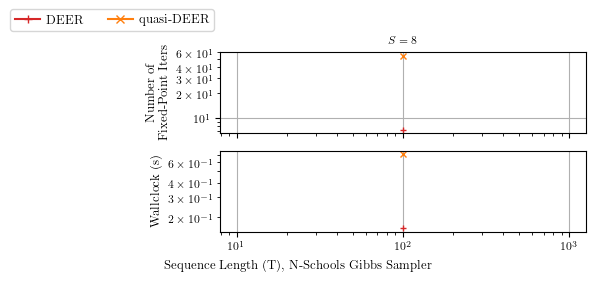

In [33]:
labs_present = [label for label, tag in tgs.items() if tag in data['alg'].unique()]
print(f"Algorithms in data: {labs_present}")
make_plot(data,
         np.sort(data['S'].dropna().unique()),
         np.sort(data['T'].dropna().unique()),
         labs=labs_present)